# Financial Time Series & Volatility Analysis

## ARIMA, EWMA, ARCH, GARCH and Out-of-Sample Backtesting

This notebook presents a complete quantitative analysis of financial time series and conditional volatility using historical SPY market data.

The analysis includes:

1. Historical adjusted prices and financial returns.
2. Descriptive statistics and distributional properties.
3. Stationarity analysis using the Augmented Dickey-Fuller test.
4. Autocorrelation and partial autocorrelation diagnostics.
5. ARIMA modeling and forecasting.
6. Exponentially Weighted Moving Average volatility.
7. ARCH and GARCH conditional-volatility models.
8. Volatility persistence and long-run variance.
9. Out-of-sample comparison of EWMA and GARCH.
10. Professional visualizations and financial interpretation.

> **Educational disclaimer:** This notebook is a quantitative financial simulator. Its results are not investment advice, guaranteed forecasts, or recommendations to buy or sell financial instruments.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "src").exists():
    for candidate in Path.cwd().parents:
        if (candidate / "src").exists():
            project_root = candidate
            break

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.arima_model import (
    calculate_forecast_metrics,
    fit_arima_model,
    forecast_arima_model,
)
from src.data_loader import load_market_data
from src.ewma_volatility import (
    calculate_ewma_volatility,
    forecast_ewma_volatility,
)
from src.garch_model import (
    calculate_persistence,
    calculate_unconditional_variance,
    fit_volatility_model,
    forecast_volatility_model,
)
from src.returns import calculate_return_statistics
from src.stationarity import (
    calculate_correlation_diagnostics,
    run_adf_test,
)
from src.volatility_backtest import (
    compare_volatility_models,
)
from src.visualization import (
    plot_acf_pacf,
    plot_backtest_comparison,
    plot_conditional_volatility,
    plot_price_history,
    plot_return_analysis,
    plot_volatility_forecast,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.6f}".format)

print(f"Python executable: {sys.executable}")
print(f"Project root: {project_root}")
print("Quantitative modules imported successfully.")

Python executable: c:\Users\Admin\Documents\Utech\Proyectos\financial-time-series-volatility-engine\.venv\Scripts\python.exe
Project root: c:\Users\Admin\Documents\Utech\Proyectos\financial-time-series-volatility-engine
Quantitative modules imported successfully.


## 1. Historical Market Data

The analysis uses adjusted daily closing prices for the SPDR S&P 500 ETF Trust (SPY) from January 2021 through December 2025.

Adjusted prices incorporate the economic effect of corporate actions and provide a consistent basis for calculating returns.

The simple daily return is:

\[
R_t = \frac{P_t}{P_{t-1}} - 1
\]

The continuously compounded logarithmic return is:

\[
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
\]

A series containing \(n\) prices produces \(n-1\) returns because the first price has no preceding observation.

The preparation process includes:

1. Downloading adjusted market prices.
2. Sorting observations chronologically.
3. Removing missing and non-finite values.
4. Validating that all prices are positive.
5. Calculating simple and logarithmic returns.
6. Aligning every return with its corresponding trading date.

In [3]:
market_data = load_market_data(
    ticker="SPY",
    start_date="2021-01-01",
    end_date="2026-01-01",
)

prices = market_data.prices
simple_returns = market_data.simple_returns
log_returns = market_data.log_returns

return_statistics = calculate_return_statistics(
    simple_returns.to_numpy()
)

market_summary = pd.DataFrame(
    {
        "Metric": [
            "Asset",
            "First trading date",
            "Last trading date",
            "Price observations",
            "Return observations",
            "Average daily return",
            "Daily volatility",
            "Annualized return",
            "Annualized volatility",
            "Cumulative return",
            "Worst daily return",
            "Best daily return",
            "Skewness",
            "Excess kurtosis",
        ],
        "Value": [
            market_data.ticker,
            str(prices.index[0].date()),
            str(prices.index[-1].date()),
            f"{prices.size:,}",
            f"{simple_returns.size:,}",
            f"{return_statistics.mean_daily_return:.4%}",
            f"{return_statistics.daily_volatility:.4%}",
            f"{return_statistics.annualized_return:.2%}",
            f"{return_statistics.annualized_volatility:.2%}",
            f"{return_statistics.cumulative_return:.2%}",
            f"{return_statistics.minimum_return:.4%}",
            f"{return_statistics.maximum_return:.4%}",
            f"{return_statistics.skewness:.6f}",
            f"{return_statistics.excess_kurtosis:.6f}",
        ],
    }
)

display(
    market_summary.style.set_caption(
        "SPY Market and Return Summary"
    )
)

latest_observations = pd.DataFrame(
    {
        "Adjusted price": prices.tail(),
        "Simple return": simple_returns.tail(),
        "Log return": log_returns.tail(),
    }
)

display(
    latest_observations.style.set_caption(
        "Latest Market Observations"
    )
)

,Metric,Value
0,Asset,SPY
1,First trading date,2021-01-04
2,Last trading date,2025-12-31
3,Price observations,"1,255"
4,Return observations,"1,254"
5,Average daily return,0.0603%
6,Daily volatility,1.0779%
7,Annualized return,15.20%
8,Annualized volatility,17.11%
9,Cumulative return,98.08%


,Adjusted price,Simple return,Log return
Date,,,
2025-12-24 00:00:00,685.029480,0.003518,0.003512
2025-12-26 00:00:00,684.960022,-0.000101,-0.000101
2025-12-29 00:00:00,682.519043,-0.003564,-0.003570
2025-12-30 00:00:00,681.685608,-0.001221,-0.001222
2025-12-31 00:00:00,676.635010,-0.007409,-0.007437


## 2. Price and Return Behavior

Financial prices and returns describe different aspects of the same asset.

- **Prices** often exhibit trends and are commonly non-stationary.
- **Returns** measure proportional changes and are usually more appropriate for statistical modeling.
- Large positive and negative returns tend to appear in groups, producing **volatility clustering**.
- Financial returns frequently display heavier tails than a normal distribution.
- Negative skewness indicates a longer or more severe left tail.
- Positive excess kurtosis indicates a greater frequency of extreme observations than under normality.

The visual analysis below examines the historical price path, daily returns, and empirical return distribution.

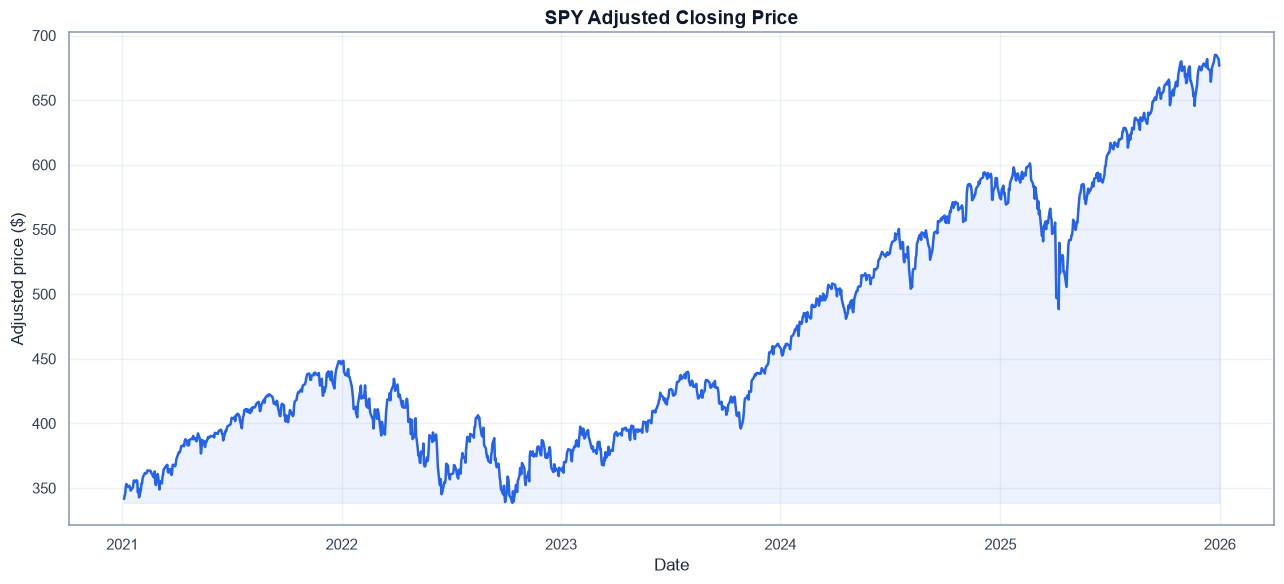

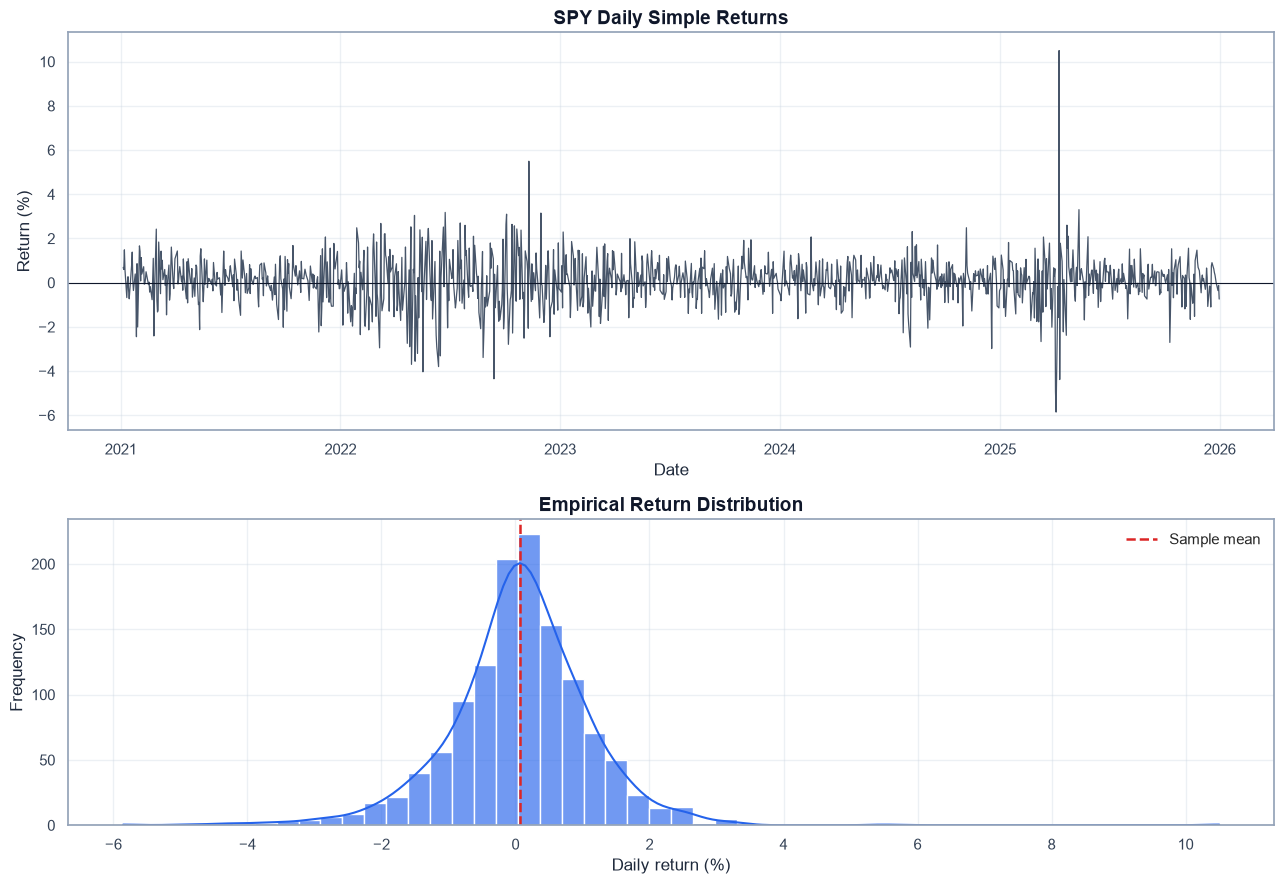

In [4]:
price_figure = plot_price_history(
    prices,
    ticker=market_data.ticker,
)

plt.show()

return_figure = plot_return_analysis(
    simple_returns,
    ticker=market_data.ticker,
)

plt.show()

## 3. Stationarity and Serial Dependence

A time series is weakly stationary when its principal statistical properties remain stable through time:

\[
E[X_t] = \mu
\]

\[
\operatorname{Var}(X_t) = \sigma^2
\]

\[
\operatorname{Cov}(X_t, X_{t-k}) = \gamma_k
\]

The covariance depends on the lag \(k\), not on the specific calendar date.

### Augmented Dickey-Fuller test

The ADF test evaluates:

\[
H_0: \text{The series contains a unit root and is non-stationary}
\]

\[
H_1: \text{The series is stationary}
\]

At a 5% significance level:

- If \(p < 0.05\), reject the unit-root null hypothesis.
- If \(p \geq 0.05\), there is insufficient evidence to reject non-stationarity.

Prices are commonly non-stationary, while financial returns are commonly stationary.

### ACF and PACF

The autocorrelation function is:

\[
\rho_k =
\operatorname{Corr}(R_t,R_{t-k})
\]

The partial autocorrelation function measures the direct relationship between \(R_t\) and \(R_{t-k}\) after controlling for intermediate lags.

These diagnostics help identify possible AR and MA structures.

,Series,ADF statistic,P-value,Used lags,Stationary at 5%
0,Adjusted prices,0.337415,0.978997,4,False
1,Simple returns,-22.096809,0.000000,2,True


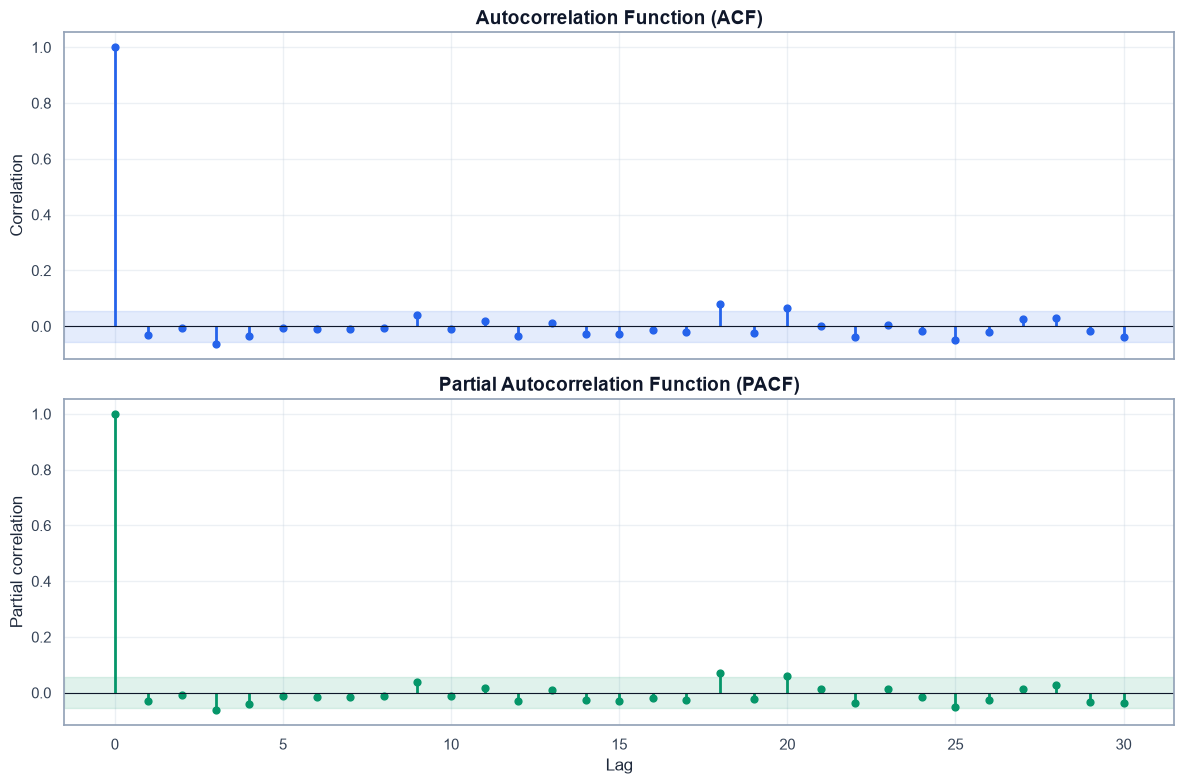

In [5]:
price_adf = run_adf_test(
    prices.to_numpy()
)

return_adf = run_adf_test(
    simple_returns.to_numpy()
)

stationarity_table = pd.DataFrame(
    {
        "Series": [
            "Adjusted prices",
            "Simple returns",
        ],
        "ADF statistic": [
            price_adf.adf_statistic,
            return_adf.adf_statistic,
        ],
        "P-value": [
            price_adf.p_value,
            return_adf.p_value,
        ],
        "Used lags": [
            price_adf.used_lags,
            return_adf.used_lags,
        ],
        "Stationary at 5%": [
            price_adf.is_stationary,
            return_adf.is_stationary,
        ],
    }
)

display(
    stationarity_table.style
    .format(
        {
            "ADF statistic": "{:.6f}",
            "P-value": "{:.6f}",
        }
    )
    .set_caption(
        "Augmented Dickey-Fuller Test Results"
    )
)

correlation_figure = plot_acf_pacf(
    simple_returns.to_numpy(),
    lags=30,
)

plt.show()

## 4. ARIMA Return Modeling

An ARIMA model combines three components:

\[
ARIMA(p,d,q)
\]

where:

- \(p\) is the autoregressive order;
- \(d\) is the number of differences;
- \(q\) is the moving-average order.

Because daily returns are already stationary, the integration order is set to:

\[
d=0
\]

An ARMA representation for stationary returns is:

\[
R_t =
c
+
\sum_{i=1}^{p}\phi_iR_{t-i}
+
\varepsilon_t
+
\sum_{j=1}^{q}\theta_j\varepsilon_{t-j}
\]

The model attempts to explain the conditional mean of returns using previous returns and previous forecast errors.

This analysis uses an ARIMA(1,0,1) specification and preserves the final 30 observations for out-of-sample evaluation.

Forecast quality is evaluated using:

\[
MAE =
\frac{1}{n}
\sum_{t=1}^{n}
|R_t-\widehat{R}_t|
\]

\[
RMSE =
\sqrt{
\frac{1}{n}
\sum_{t=1}^{n}
(R_t-\widehat{R}_t)^2
}
\]

MAPE is also reported, but it must be interpreted cautiously because financial returns can be very close to zero.

,Metric,Value
0,Model,"ARIMA(1,0,1)"
1,Training observations,"1,224"
2,Forecast observations,30
3,AIC,-7583.029701
4,BIC,-7562.596724
5,HQIC,-7575.339658
6,MAE,0.005540
7,RMSE,0.006870
8,MAPE,116.85%


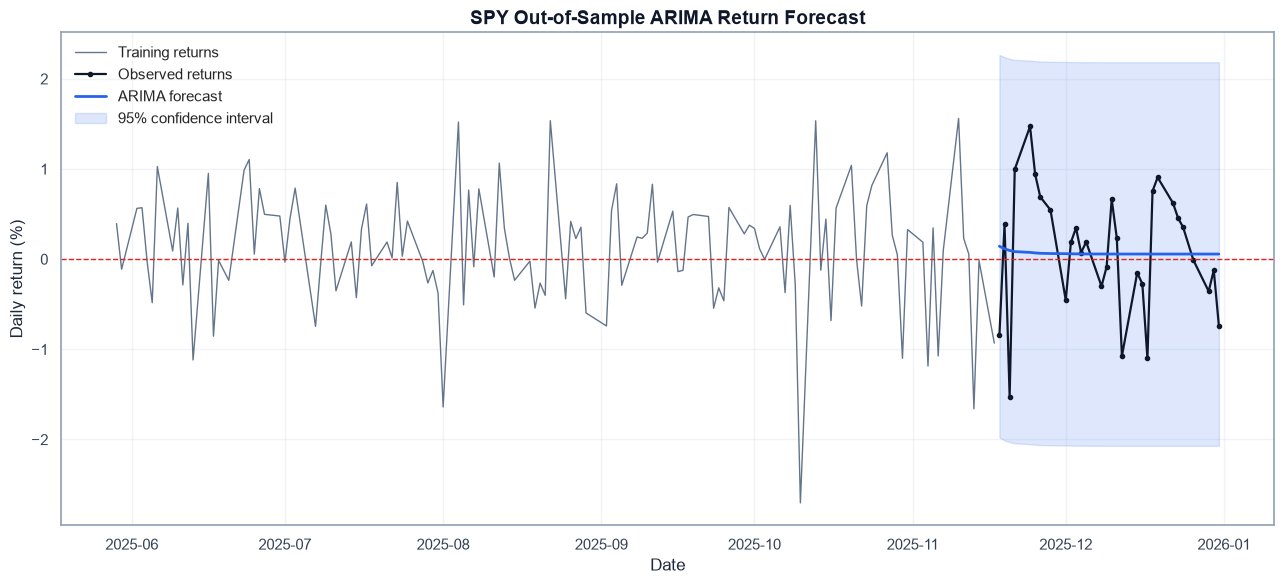

In [6]:
forecast_horizon = 30

training_returns = simple_returns.iloc[
    :-forecast_horizon
]
testing_returns = simple_returns.iloc[
    -forecast_horizon:
]

arima_model = fit_arima_model(
    training_returns.to_numpy(),
    order=(1, 0, 1),
)

arima_forecast = forecast_arima_model(
    arima_model,
    steps=forecast_horizon,
    confidence_level=0.95,
)

arima_metrics = calculate_forecast_metrics(
    testing_returns.to_numpy(),
    arima_forecast.predicted_mean,
)

arima_summary = pd.DataFrame(
    {
        "Metric": [
            "Model",
            "Training observations",
            "Forecast observations",
            "AIC",
            "BIC",
            "HQIC",
            "MAE",
            "RMSE",
            "MAPE",
        ],
        "Value": [
            "ARIMA(1,0,1)",
            f"{arima_model.observations:,}",
            f"{arima_forecast.steps:,}",
            f"{arima_model.aic:.6f}",
            f"{arima_model.bic:.6f}",
            f"{arima_model.hqic:.6f}",
            f"{arima_metrics.mean_absolute_error:.6f}",
            f"{arima_metrics.root_mean_squared_error:.6f}",
            (
                f"{arima_metrics.mean_absolute_percentage_error:.2%}"
            ),
        ],
    }
)

display(
    arima_summary.style.set_caption(
        "ARIMA Model and Forecast Evaluation"
    )
)

figure, axis = plt.subplots(
    figsize=(13, 6)
)

axis.plot(
    training_returns.index[-120:],
    training_returns.iloc[-120:] * 100.0,
    color="#64748B",
    linewidth=1.0,
    label="Training returns",
)

axis.plot(
    testing_returns.index,
    testing_returns.to_numpy() * 100.0,
    color="#0F172A",
    linewidth=1.6,
    marker="o",
    markersize=3,
    label="Observed returns",
)

axis.plot(
    testing_returns.index,
    arima_forecast.predicted_mean * 100.0,
    color="#2563EB",
    linewidth=2.0,
    label="ARIMA forecast",
)

axis.fill_between(
    testing_returns.index,
    arima_forecast.lower_bound * 100.0,
    arima_forecast.upper_bound * 100.0,
    color="#2563EB",
    alpha=0.15,
    label="95% confidence interval",
)

axis.axhline(
    0.0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.0,
)

axis.set_title(
    "SPY Out-of-Sample ARIMA Return Forecast"
)
axis.set_xlabel("Date")
axis.set_ylabel("Daily return (%)")
axis.legend()
axis.grid(alpha=0.25)

figure.tight_layout()
plt.show()

## 5. EWMA Volatility

The Exponentially Weighted Moving Average model estimates conditional variance using:

\[
\sigma_t^2
=
\lambda \sigma_{t-1}^2
+
(1-\lambda)R_{t-1}^2
\]

where:

- \(\sigma_t^2\) is the conditional variance;
- \(R_{t-1}^2\) is the most recent squared return;
- \(\lambda\) is the decay factor.

This analysis uses:

\[
\lambda = 0.94
\]

The weight assigned to a return \(k\) periods in the past is:

\[
w_k =
(1-\lambda)\lambda^k
\]

Therefore, recent observations receive more weight than older observations.

A large market movement increases the volatility estimate immediately. If subsequent returns are calm, its influence gradually declines.

EWMA has no separate long-run variance target. Its expected multi-period variance forecast remains equal to the next one-step forecast.

,Metric,Value
0,Decay factor,0.94
1,Observations,"1,254"
2,Initial daily volatility,1.0779%
3,Latest daily volatility,0.6510%
4,Latest annualized volatility,10.33%
5,20-day forecasted daily volatility,0.6567%
6,20-day forecasted annualized volatility,10.43%


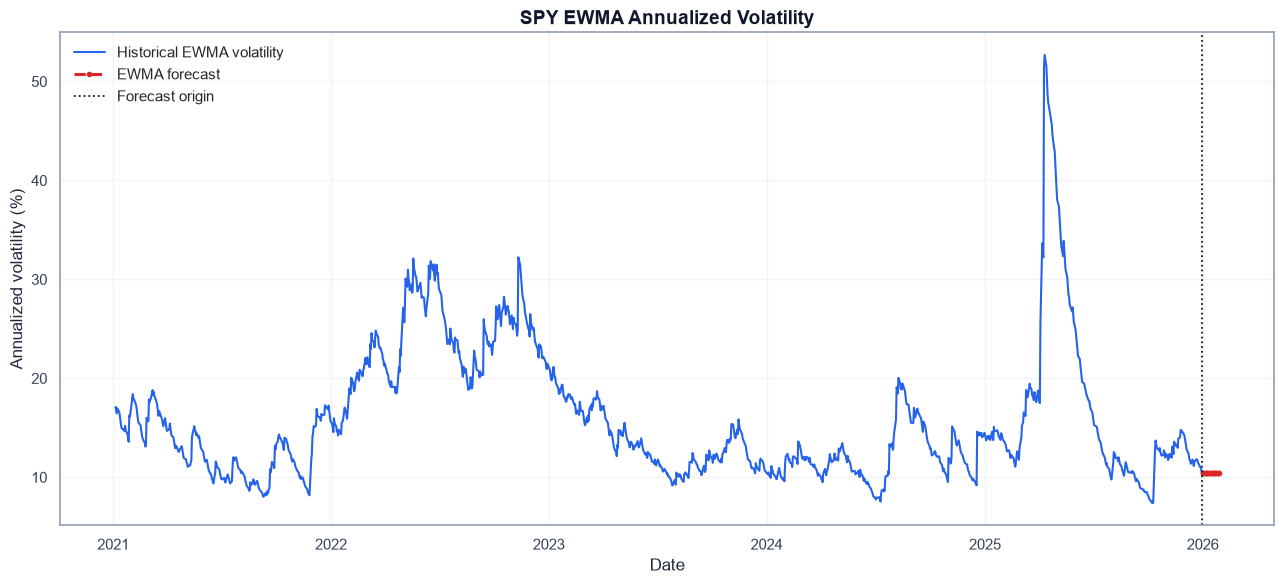

In [7]:
ewma_result = calculate_ewma_volatility(
    simple_returns.to_numpy(),
    decay_factor=0.94,
)

ewma_forecast = forecast_ewma_volatility(
    simple_returns.to_numpy(),
    steps=20,
    decay_factor=0.94,
)

ewma_summary = pd.DataFrame(
    {
        "Metric": [
            "Decay factor",
            "Observations",
            "Initial daily volatility",
            "Latest daily volatility",
            "Latest annualized volatility",
            "20-day forecasted daily volatility",
            "20-day forecasted annualized volatility",
        ],
        "Value": [
            f"{ewma_result.decay_factor:.2f}",
            f"{ewma_result.observations:,}",
            f"{np.sqrt(ewma_result.initial_variance):.4%}",
            (
                f"{ewma_result.conditional_volatilities[-1]:.4%}"
            ),
            (
                f"{ewma_result.annualized_volatilities[-1]:.2%}"
            ),
            (
                f"{ewma_forecast.volatility_forecasts[-1]:.4%}"
            ),
            (
                f"{ewma_forecast.annualized_volatility_forecasts[-1]:.2%}"
            ),
        ],
    }
)

display(
    ewma_summary.style.set_caption(
        "EWMA Volatility Summary"
    )
)

future_dates = pd.bdate_range(
    start=(
        simple_returns.index[-1]
        + pd.offsets.BDay(1)
    ),
    periods=ewma_forecast.steps,
)

figure, axis = plt.subplots(
    figsize=(13, 6)
)

axis.plot(
    simple_returns.index,
    ewma_result.annualized_volatilities * 100.0,
    color="#2563EB",
    linewidth=1.5,
    label="Historical EWMA volatility",
)

axis.plot(
    future_dates,
    (
        ewma_forecast
        .annualized_volatility_forecasts
        * 100.0
    ),
    color="#DC2626",
    linewidth=2.2,
    linestyle="--",
    marker="o",
    markersize=3,
    label="EWMA forecast",
)

axis.axvline(
    simple_returns.index[-1],
    color="#0F172A",
    linestyle=":",
    linewidth=1.3,
    label="Forecast origin",
)

axis.set_title(
    "SPY EWMA Annualized Volatility"
)
axis.set_xlabel("Date")
axis.set_ylabel("Annualized volatility (%)")
axis.legend()
axis.grid(alpha=0.25)

figure.tight_layout()
plt.show()

## 6. ARCH and GARCH Volatility Models

Financial returns often exhibit volatility clustering:

- large movements tend to be followed by large movements;
- calm periods tend to be followed by calm periods;
- the direction may change, but the magnitude remains persistent.

### ARCH model

An ARCH(\(p\)) model represents conditional variance as:

\[
\sigma_t^2
=
\omega
+
\sum_{i=1}^{p}
\alpha_i\varepsilon_{t-i}^2
\]

Past squared shocks determine current volatility.

### GARCH model

A GARCH(\(p,q\)) model adds previous conditional variances:

\[
\sigma_t^2
=
\omega
+
\sum_{i=1}^{p}
\alpha_i\varepsilon_{t-i}^2
+
\sum_{j=1}^{q}
\beta_j\sigma_{t-j}^2
\]

For GARCH(1,1):

\[
\sigma_t^2
=
\omega
+
\alpha\varepsilon_{t-1}^2
+
\beta\sigma_{t-1}^2
\]

The coefficient \(\alpha\) measures the immediate reaction to new shocks. The coefficient \(\beta\) measures volatility persistence.

Total persistence is:

\[
\alpha+\beta
\]

For a covariance-stationary GARCH(1,1):

\[
\alpha+\beta<1
\]

The unconditional long-run variance is:

\[
\sigma_{\infty}^2
=
\frac{\omega}
{1-\alpha-\beta}
\]

High persistence means that volatility shocks decay slowly.

,Parameter,Estimate
0,omega,0.03555137
1,alpha[1],0.10998343
2,beta[1],0.85786579


,Metric,Value
0,Model,"GARCH(1,1)"
1,Distribution,normal
2,Observations,"1,254"
3,Log-likelihood,-1719.487150
4,AIC,3444.974300
5,BIC,3460.376581
6,Persistence,0.967849
7,Long-run daily volatility,1.0516%
8,Latest conditional volatility,0.6827%
9,Latest annualized volatility,10.84%


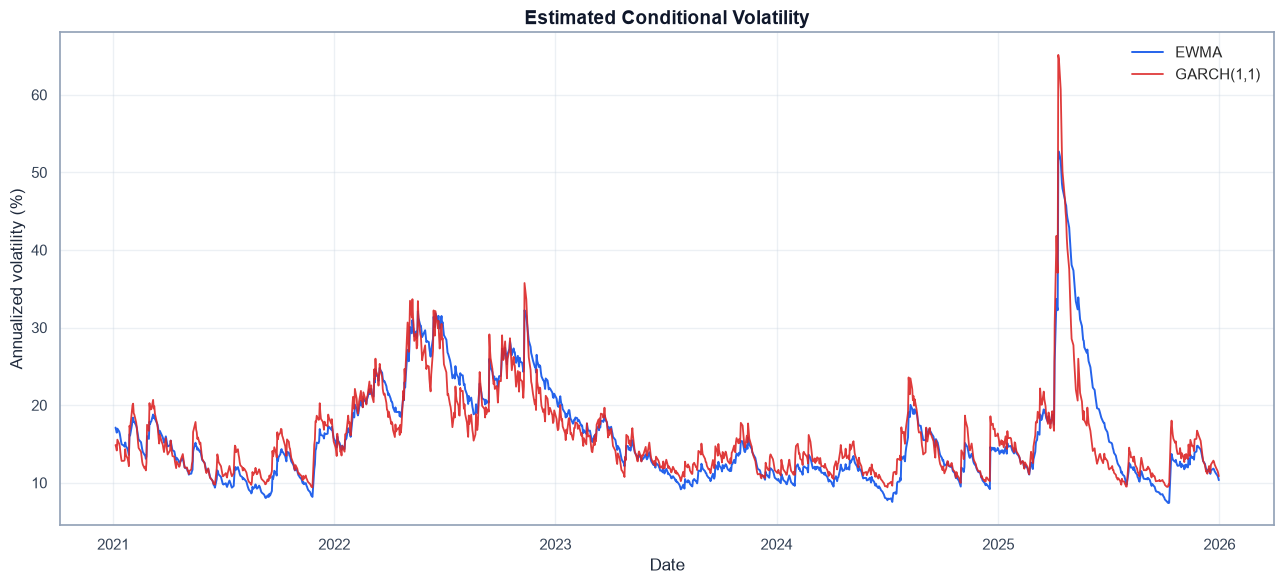

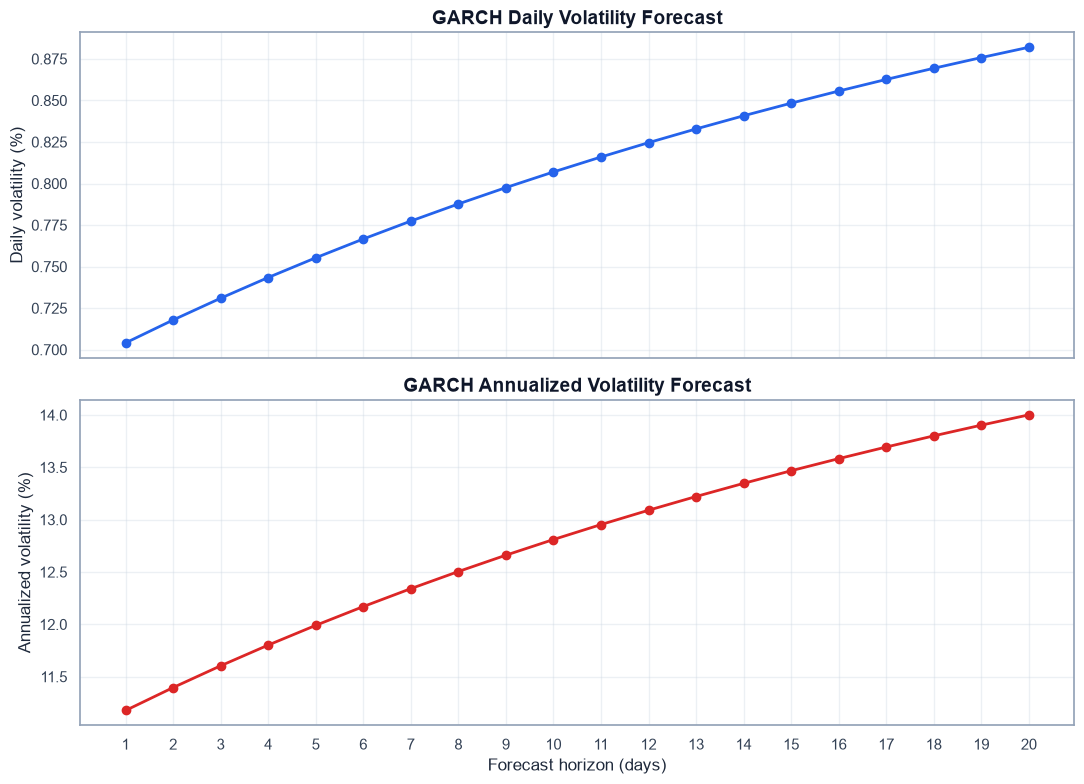

In [8]:
garch_model = fit_volatility_model(
    simple_returns.to_numpy(),
    model_type="GARCH",
    p=1,
    q=1,
    distribution="normal",
    mean_model="zero",
)

garch_forecast = forecast_volatility_model(
    garch_model,
    steps=20,
)

garch_persistence = calculate_persistence(
    garch_model
)

garch_long_run_variance = (
    calculate_unconditional_variance(
        garch_model
    )
)

parameter_table = pd.DataFrame(
    {
        "Parameter": list(
            garch_model.parameters.keys()
        ),
        "Estimate": list(
            garch_model.parameters.values()
        ),
    }
)

model_table = pd.DataFrame(
    {
        "Metric": [
            "Model",
            "Distribution",
            "Observations",
            "Log-likelihood",
            "AIC",
            "BIC",
            "Persistence",
            "Long-run daily volatility",
            "Latest conditional volatility",
            "Latest annualized volatility",
        ],
        "Value": [
            "GARCH(1,1)",
            garch_model.distribution,
            f"{garch_model.observations:,}",
            f"{garch_model.log_likelihood:.6f}",
            f"{garch_model.aic:.6f}",
            f"{garch_model.bic:.6f}",
            f"{garch_persistence:.6f}",
            f"{np.sqrt(garch_long_run_variance):.4%}",
            (
                f"{garch_model.conditional_volatilities[-1]:.4%}"
            ),
            (
                f"{garch_model.conditional_volatilities[-1] * np.sqrt(252):.2%}"
            ),
        ],
    }
)

display(
    parameter_table.style
    .format({"Estimate": "{:.8f}"})
    .set_caption(
        "Estimated GARCH Parameters"
    )
)

display(
    model_table.style.set_caption(
        "GARCH Model Summary"
    )
)

volatility_figure = plot_conditional_volatility(
    simple_returns.index,
    ewma_result.conditional_volatilities,
    garch_model.conditional_volatilities,
)

plt.show()

forecast_figure = plot_volatility_forecast(
    garch_forecast
)

plt.show()

## 7. Out-of-Sample Volatility Backtesting

A volatility model should be evaluated using observations that were not used to estimate it.

For every forecast origin:

1. The model receives only historical returns.
2. A conditional variance forecast is generated.
3. The forecast is compared with the next realized squared return.
4. The estimation window advances through time.
5. Future information is never used.

The realized-variance proxy is:

\[
RV_t = R_t^2
\]

The forecast error is:

\[
e_t =
\widehat{\sigma}_t^2
-
R_t^2
\]

The evaluation measures include:

### Mean Absolute Error

\[
MAE =
\frac{1}{n}
\sum_{t=1}^{n}
\left|
\widehat{\sigma}_t^2-R_t^2
\right|
\]

### Root Mean Squared Error

\[
RMSE =
\sqrt{
\frac{1}{n}
\sum_{t=1}^{n}
\left(
\widehat{\sigma}_t^2-R_t^2
\right)^2
}
\]

### QLIKE loss

\[
QLIKE =
\frac{1}{n}
\sum_{t=1}^{n}
\left[
\ln(\widehat{\sigma}_t^2)
+
\frac{R_t^2}
{\widehat{\sigma}_t^2}
\right]
\]

Lower MAE, RMSE, and QLIKE values indicate better forecasts.

QLIKE is especially useful for volatility evaluation because the true conditional variance is not directly observable.

,Metric,EWMA,GARCH
0,Out-of-sample observations,754.0000000000,754.0000000000
1,Variance MAE,0.0001112960,0.0001071991
2,Variance RMSE,0.0004407855,0.0004482507
3,QLIKE loss,-8.4639373849,-8.1680380813
4,Mean realized variance,0.0000942384,0.0000942384
5,Mean forecast variance,0.0000971281,0.0000879121
6,Forecast bias,0.0000028897,-0.0000063263
7,Variance correlation,0.1880537757,-0.0200372842


Best model according to QLIKE: EWMA


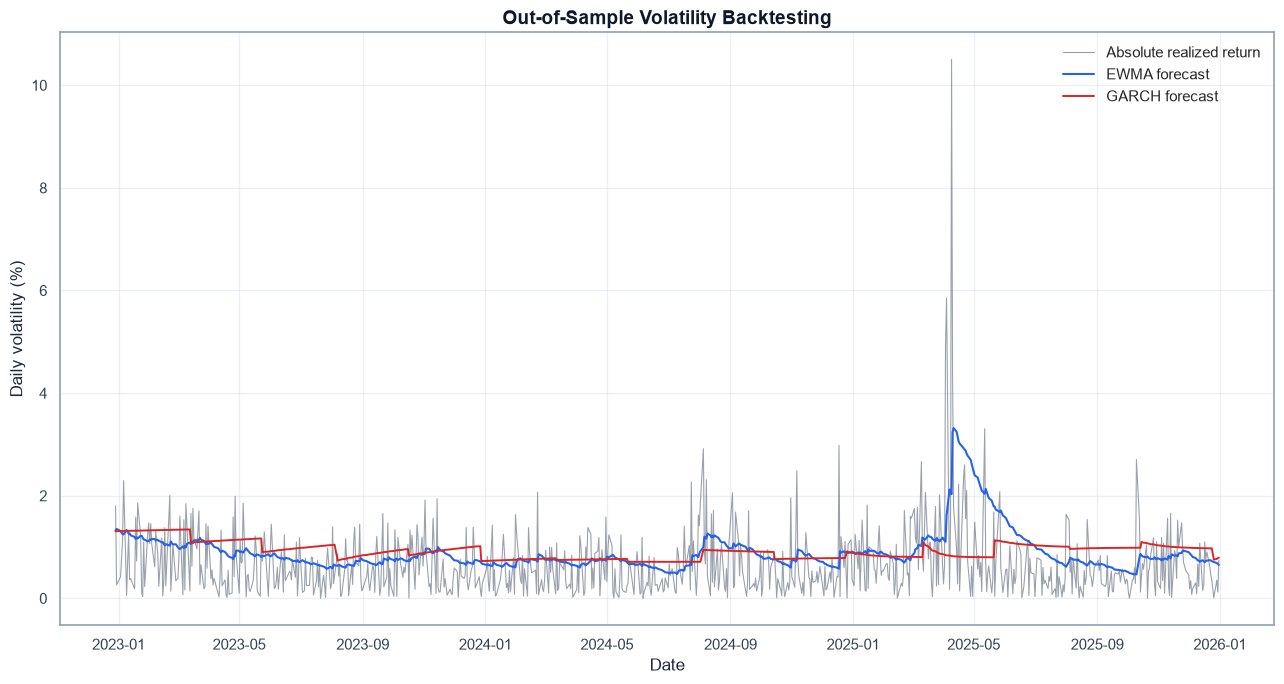

In [9]:
estimation_window = 500

volatility_comparison = compare_volatility_models(
    simple_returns.to_numpy(),
    estimation_window=estimation_window,
    decay_factor=0.94,
    refit_frequency=50,
    distribution="normal",
)

comparison_table = pd.DataFrame(
    {
        "Metric": [
            "Out-of-sample observations",
            "Variance MAE",
            "Variance RMSE",
            "QLIKE loss",
            "Mean realized variance",
            "Mean forecast variance",
            "Forecast bias",
            "Variance correlation",
        ],
        "EWMA": [
            volatility_comparison.ewma.metrics.observations,
            volatility_comparison.ewma.metrics.mean_absolute_error,
            volatility_comparison.ewma.metrics.root_mean_squared_error,
            volatility_comparison.ewma.metrics.qlike_loss,
            volatility_comparison.ewma.metrics.mean_realized_variance,
            volatility_comparison.ewma.metrics.mean_forecast_variance,
            volatility_comparison.ewma.metrics.forecast_bias,
            volatility_comparison.ewma.metrics.variance_correlation,
        ],
        "GARCH": [
            volatility_comparison.garch.metrics.observations,
            volatility_comparison.garch.metrics.mean_absolute_error,
            volatility_comparison.garch.metrics.root_mean_squared_error,
            volatility_comparison.garch.metrics.qlike_loss,
            volatility_comparison.garch.metrics.mean_realized_variance,
            volatility_comparison.garch.metrics.mean_forecast_variance,
            volatility_comparison.garch.metrics.forecast_bias,
            volatility_comparison.garch.metrics.variance_correlation,
        ],
    }
)

display(
    comparison_table.style
    .format(
        {
            "EWMA": "{:.10f}",
            "GARCH": "{:.10f}",
        }
    )
    .set_caption(
        "Out-of-Sample Volatility Model Comparison"
    )
)

print(
    "Best model according to QLIKE:",
    volatility_comparison.best_model_by_qlike,
)

out_of_sample_dates = simple_returns.index[
    estimation_window:
]

backtest_figure = plot_backtest_comparison(
    out_of_sample_dates,
    volatility_comparison,
)

plt.show()

In [10]:
executive_summary = pd.DataFrame(
    {
        "Key Indicator": [
            "Asset",
            "Analysis period",
            "Price observations",
            "Return observations",
            "Annualized return",
            "Annualized volatility",
            "Return skewness",
            "Return excess kurtosis",
            "Price ADF p-value",
            "Return ADF p-value",
            "Returns stationary at 5%",
            "ARIMA forecast RMSE",
            "Latest EWMA annualized volatility",
            "Latest GARCH annualized volatility",
            "GARCH persistence",
            "GARCH long-run daily volatility",
            "Best volatility model by QLIKE",
            "EWMA QLIKE",
            "GARCH QLIKE",
        ],
        "Value": [
            market_data.ticker,
            (
                f"{prices.index[0].date()} "
                f"to {prices.index[-1].date()}"
            ),
            f"{prices.size:,}",
            f"{simple_returns.size:,}",
            f"{return_statistics.annualized_return:.2%}",
            f"{return_statistics.annualized_volatility:.2%}",
            f"{return_statistics.skewness:.6f}",
            f"{return_statistics.excess_kurtosis:.6f}",
            f"{price_adf.p_value:.6f}",
            f"{return_adf.p_value:.6f}",
            str(return_adf.is_stationary),
            (
                f"{arima_metrics.root_mean_squared_error:.6f}"
            ),
            (
                f"{ewma_result.annualized_volatilities[-1]:.2%}"
            ),
            (
                f"{garch_model.conditional_volatilities[-1] * np.sqrt(252):.2%}"
            ),
            f"{garch_persistence:.6f}",
            f"{np.sqrt(garch_long_run_variance):.4%}",
            (
                volatility_comparison
                .best_model_by_qlike
            ),
            (
                f"{volatility_comparison.ewma.metrics.qlike_loss:.6f}"
            ),
            (
                f"{volatility_comparison.garch.metrics.qlike_loss:.6f}"
            ),
        ],
    }
)

display(
    executive_summary.style.set_caption(
        "Executive Financial Time-Series Summary"
    )
)

,Key Indicator,Value
0,Asset,SPY
1,Analysis period,2021-01-04 to 2025-12-31
2,Price observations,"1,255"
3,Return observations,"1,254"
4,Annualized return,15.20%
5,Annualized volatility,17.11%
6,Return skewness,0.294430
7,Return excess kurtosis,9.143433
8,Price ADF p-value,0.978997
9,Return ADF p-value,0.000000


## 8. Conclusions and Practical Interpretation

### Main findings

1. **Prices and returns have different statistical behavior.**  
   SPY adjusted prices exhibit a persistent trend and are generally non-stationary. Daily returns remove most of this trend and provide a more appropriate series for statistical modeling.

2. **Daily returns are stationary.**  
   The Augmented Dickey-Fuller test rejects the unit-root hypothesis for returns at the 5% significance level. This supports the use of ARIMA, EWMA, ARCH, and GARCH models.

3. **Return predictability is limited.**  
   The ARIMA model generally produces forecasts close to zero. This reflects the weak linear predictability commonly observed in liquid financial markets.

4. **Volatility is more predictable than return direction.**  
   Although the sign of tomorrow's return is difficult to forecast, periods of high and low volatility tend to persist.

5. **EWMA reacts quickly to new shocks.**  
   With a decay factor of 0.94, recent squared returns receive greater weight. This makes EWMA responsive to sudden changes in market risk.

6. **GARCH captures volatility persistence and mean reversion.**  
   The ARCH coefficient measures the immediate impact of new shocks, while the GARCH coefficient measures the persistence of previous volatility.

7. **Persistence is financially important.**  
   A value of \(\alpha+\beta\) close to one indicates that volatility shocks disappear slowly. Lower persistence implies faster reversion toward long-run variance.

8. **Out-of-sample evaluation is essential.**  
   In-sample fit does not guarantee forecasting quality. EWMA and GARCH must be compared using observations that were unavailable during estimation.

9. **The preferred model depends on the loss function.**  
   A model may produce lower MAE while another produces lower QLIKE. Model selection must reflect the objective of the analysis.

### Practical applications

This engine can support:

- market-risk monitoring;
- volatility forecasting;
- dynamic position sizing;
- Value at Risk inputs;
- derivatives analysis;
- portfolio-risk allocation;
- stress testing;
- hedging decisions;
- model comparison;
- quantitative research.

### Limitations

The analysis is subject to important limitations:

- squared daily returns are noisy proxies for latent variance;
- ARIMA captures linear mean dependence only;
- standard GARCH assumes symmetric volatility responses;
- normal innovations may underestimate extreme tails;
- structural breaks can change estimated parameters;
- transaction costs and liquidity effects are excluded;
- forecasts are conditional on historical relationships remaining relevant;
- statistical forecasts are not guaranteed market outcomes.

Possible extensions include Student-t GARCH, EGARCH, GJR-GARCH, realized volatility, regime-switching models, multivariate GARCH, and machine-learning volatility forecasts.

---

## Final Statement

The Financial Time Series & Volatility Engine integrates market-data preparation, return analysis, stationarity testing, ARIMA forecasting, EWMA estimation, ARCH/GARCH modeling, professional visualization, and out-of-sample backtesting in a reproducible Python framework.

The project demonstrates that financial returns may be difficult to predict in direction, while their changing level of risk can be modeled, forecast, compared, and interpreted quantitatively.

> This notebook is intended for education and quantitative research. It does not constitute investment advice or a guarantee of future performance.